In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv('Churn_Modelling.csv')

print(df.head())
print("Dataset Shape:", df.shape)

   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4         790

In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df['Exited'].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB

Missing Values:
RowNumber          0
CustomerId         0
Surname       

In [4]:
X = df.drop(
    ['RowNumber', 'CustomerId', 'Surname', 'Exited'],
    axis=1
)

y = df['Exited']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print(X.head())

Feature Shape: (10000, 10)
Target Shape: (10000,)
   CreditScore Geography  Gender  Age  Tenure    Balance  NumOfProducts  \
0          619    France  Female   42       2       0.00              1   
1          608     Spain  Female   41       1   83807.86              1   
2          502    France  Female   42       8  159660.80              3   
3          699    France  Female   39       1       0.00              2   
4          850     Spain  Female   43       2  125510.82              1   

   HasCrCard  IsActiveMember  EstimatedSalary  
0          1               1        101348.88  
1          0               1        112542.58  
2          1               0        113931.57  
3          0               0         93826.63  
4          1               1         79084.10  


In [5]:
X = pd.get_dummies(
    X,
    columns=['Geography', 'Gender'],
    drop_first=True,
    dtype=int
)

print(X.head())
print("Encoded Feature Shape:", X.shape)

   CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619   42       2       0.00              1          1   
1          608   41       1   83807.86              1          0   
2          502   42       8  159660.80              3          1   
3          699   39       1       0.00              2          0   
4          850   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Geography_Germany  Geography_Spain  \
0               1        101348.88                  0                0   
1               1        112542.58                  0                1   
2               0        113931.57                  0                0   
3               0         93826.63                  0                0   
4               1         79084.10                  0                1   

   Gender_Male  
0            0  
1            0  
2            0  
3            0  
4            0  
Encoded Feature Shape: (10000, 11)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 11)
Testing Data: (2000, 11)


In [7]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training and testing data normalized successfully.")

Training and testing data normalized successfully.


In [8]:
#Build the basic neural network
model = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation='relu',
    solver='adam',
    max_iter=300,
    random_state=42
)

model.fit(X_train, y_train)

print("Basic Neural Network trained successfully.")

Basic Neural Network trained successfully.


In [9]:
y_pred = model.predict(X_test)

print("Basic Model Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Stay', 'Leave'],
    zero_division=0
))

Basic Model Accuracy: 87.25 %

Confusion Matrix:
[[1551   42]
 [ 213  194]]

Classification Report:
              precision    recall  f1-score   support

        Stay       0.88      0.97      0.92      1593
       Leave       0.82      0.48      0.60       407

    accuracy                           0.87      2000
   macro avg       0.85      0.73      0.76      2000
weighted avg       0.87      0.87      0.86      2000



In [10]:
improved_model = MLPClassifier(
    hidden_layer_sizes=(64, 32, 16),
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=15,
    random_state=42
)

# Give greater importance to customers who leave
class_counts = y_train.value_counts()
class_weights = {
    cls: len(y_train) / (2 * count)
    for cls, count in class_counts.items()
}

sample_weights = y_train.map(class_weights).to_numpy()

improved_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

print("Improved Neural Network trained successfully.")

Improved Neural Network trained successfully.


In [11]:
y_pred_improved = improved_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_improved)
cm = confusion_matrix(y_test, y_pred_improved)

print("Improved Model Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_improved,
    target_names=['Stay', 'Leave'],
    zero_division=0
))

Improved Model Accuracy: 76.15 %

Confusion Matrix:
[[1210  383]
 [  94  313]]

Classification Report:
              precision    recall  f1-score   support

        Stay       0.93      0.76      0.84      1593
       Leave       0.45      0.77      0.57       407

    accuracy                           0.76      2000
   macro avg       0.69      0.76      0.70      2000
weighted avg       0.83      0.76      0.78      2000



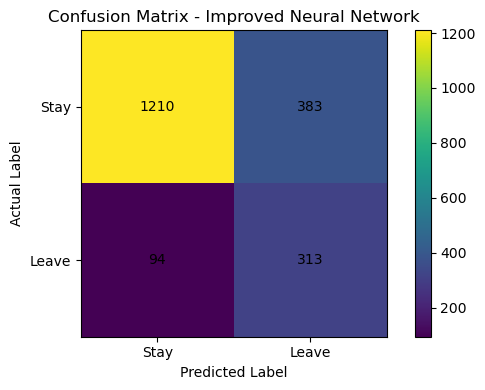

In [12]:
plt.figure(figsize=(6, 4))

plt.imshow(cm, interpolation='nearest')
plt.title('Confusion Matrix - Improved Neural Network')
plt.colorbar()

plt.xticks([0, 1], ['Stay', 'Leave'])
plt.yticks([0, 1], ['Stay', 'Leave'])

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.tight_layout()
plt.show()

In [13]:
basic_accuracy = accuracy_score(y_test, model.predict(X_test))
improved_accuracy = accuracy_score(
    y_test,
    improved_model.predict(X_test)
)

print("Basic Model Accuracy:",
      round(basic_accuracy * 100, 2), "%")

print("Improved Model Accuracy:",
      round(improved_accuracy * 100, 2), "%")

Basic Model Accuracy: 87.25 %
Improved Model Accuracy: 76.15 %
